In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE = '/content/drive/MyDrive/drone-mapping'
os.makedirs(f'{DRIVE}/models', exist_ok=True)

if not os.path.exists('/content/tiles'):
    !unzip -q "{DRIVE}/data/tiles_512.zip" -d /content
!pip install -q segmentation-models-pytorch
!nvidia-smi --query-gpu=name,memory.total --format=csv


Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import glob, random, cv2, numpy as np, torch
from torch.utils.data import Dataset, DataLoader

CLASSES = ['Clutter', 'Building', 'Road', 'Tree', 'LowVeg', 'MovingCar', 'StaticCar', 'Human']
NUM_CLASSES = 8
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def list_tiles(split, originals_only=False):
    paths = sorted(glob.glob(f'/content/tiles/{split}/images/*.jpg'))
    if originals_only:
        paths = [p for p in paths
                 if 'flipped' not in os.path.basename(p) and 'shifted' not in os.path.basename(p)]
    return paths

class TileDataset(Dataset):
    def __init__(self, paths, train):
        self.paths, self.train = paths, train

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        p = self.paths[i]
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        lab = cv2.imread(p.replace('/images/', '/labels/').replace('.jpg', '.png'), cv2.IMREAD_GRAYSCALE)

        if self.train:   # on-the-fly augmentation, same transform for image and mask
            if random.random() < 0.5:
                img, lab = img[:, ::-1], lab[:, ::-1]
            if random.random() < 0.5:
                img, lab = img[::-1], lab[::-1]
            k = random.randint(0, 3)
            img, lab = np.rot90(img, k), np.rot90(lab, k)
            if random.random() < 0.5:
                a, b = random.uniform(0.8, 1.2), random.uniform(-20, 20)
                img = np.clip(img.astype(np.float32) * a + b, 0, 255)

        img = (img.astype(np.float32) / 255.0 - MEAN) / STD
        img = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1)))
        lab = torch.from_numpy(np.ascontiguousarray(lab)).long()
        return img, lab

train_paths = list_tiles('train', originals_only=True)
val_paths = list_tiles('val')
print('Train tiles:', len(train_paths), '| Val tiles:', len(val_paths))

train_dl = DataLoader(TileDataset(train_paths, True), batch_size=8, shuffle=True,
                      num_workers=2, pin_memory=True, drop_last=True)
val_dl = DataLoader(TileDataset(val_paths, False), batch_size=8, shuffle=False,
                    num_workers=2, pin_memory=True)

Train tiles: 2400 | Val tiles: 840


In [3]:
import segmentation_models_pytorch as smp

device = 'cuda'
EPOCHS = 30

model = smp.Unet('resnet34', encoder_weights='imagenet', classes=NUM_CLASSES).to(device)

ce = torch.nn.CrossEntropyLoss(ignore_index=255)
dice = smp.losses.DiceLoss(mode='multiclass', ignore_index=255)
def loss_fn(out, y):
    out = out.float()   # compute loss in full precision for stability
    return ce(out, y) + dice(out, y)

opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda')

def update_cm(cm, pred, y):
    m = y != 255
    idx = y[m] * NUM_CLASSES + pred[m]
    cm += torch.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)

def iou_from_cm(cm):
    tp = cm.diag().float()
    fp = cm.sum(0).float() - tp
    fn = cm.sum(1).float() - tp
    return tp / (tp + fp + fn).clamp(min=1)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [4]:
import time

CKPT_LAST = f'{DRIVE}/models/unet_r34_last.pth'
CKPT_BEST = f'{DRIVE}/models/unet_r34_best.pth'
start_epoch, best_miou, history = 0, 0.0, []

if os.path.exists(CKPT_LAST):
    ck = torch.load(CKPT_LAST, map_location=device, weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
    sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
    start_epoch, best_miou, history = ck['epoch'] + 1, ck['best_miou'], ck['history']
    print(f'Resuming from epoch {start_epoch + 1}')

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    model.train(); train_loss = 0.0
    for x, y in train_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            out = model(x)
        loss = loss_fn(out, y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        train_loss += loss.item()
    sched.step()

    model.eval(); val_loss = 0.0
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                out = model(x)
            val_loss += loss_fn(out, y).item()
            update_cm(cm, out.argmax(1), y)

    iou = iou_from_cm(cm).cpu().numpy()
    miou = float(iou.mean())
    pix_acc = float(cm.diag().sum() / cm.sum())
    history.append({'epoch': epoch + 1, 'train_loss': train_loss / len(train_dl),
                    'val_loss': val_loss / len(val_dl), 'miou': miou,
                    'pix_acc': pix_acc, 'iou': iou.tolist()})

    tag = ''
    if miou > best_miou:
        best_miou = miou
        torch.save(model.state_dict(), CKPT_BEST)
        tag = '  <- best'
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                'scaler': scaler.state_dict(), 'epoch': epoch, 'best_miou': best_miou,
                'history': history}, CKPT_LAST)

    h = history[-1]
    print(f"Epoch {epoch+1}/{EPOCHS} | train {h['train_loss']:.3f} | val {h['val_loss']:.3f} | "
          f"mIoU {miou:.3f} | acc {pix_acc:.3f} | {time.time()-t0:.0f}s{tag}")

Epoch 1/30 | train 1.694 | val 1.177 | mIoU 0.425 | acc 0.771 | 96s  <- best
Epoch 2/30 | train 1.261 | val 1.028 | mIoU 0.515 | acc 0.798 | 95s  <- best
Epoch 3/30 | train 1.108 | val 0.982 | mIoU 0.522 | acc 0.807 | 96s  <- best
Epoch 4/30 | train 0.999 | val 1.016 | mIoU 0.519 | acc 0.797 | 97s
Epoch 5/30 | train 0.943 | val 0.946 | mIoU 0.557 | acc 0.810 | 96s  <- best
Epoch 6/30 | train 0.893 | val 0.860 | mIoU 0.603 | acc 0.826 | 97s  <- best
Epoch 7/30 | train 0.801 | val 0.821 | mIoU 0.626 | acc 0.831 | 98s  <- best
Epoch 8/30 | train 0.796 | val 0.831 | mIoU 0.608 | acc 0.828 | 96s
Epoch 9/30 | train 0.730 | val 0.784 | mIoU 0.643 | acc 0.840 | 97s  <- best
Epoch 10/30 | train 0.717 | val 0.804 | mIoU 0.631 | acc 0.833 | 97s
Epoch 11/30 | train 0.664 | val 0.750 | mIoU 0.658 | acc 0.848 | 96s  <- best
Epoch 12/30 | train 0.626 | val 0.714 | mIoU 0.669 | acc 0.856 | 97s  <- best
Epoch 13/30 | train 0.605 | val 0.726 | mIoU 0.653 | acc 0.851 | 96s
Epoch 14/30 | train 0.591 | val

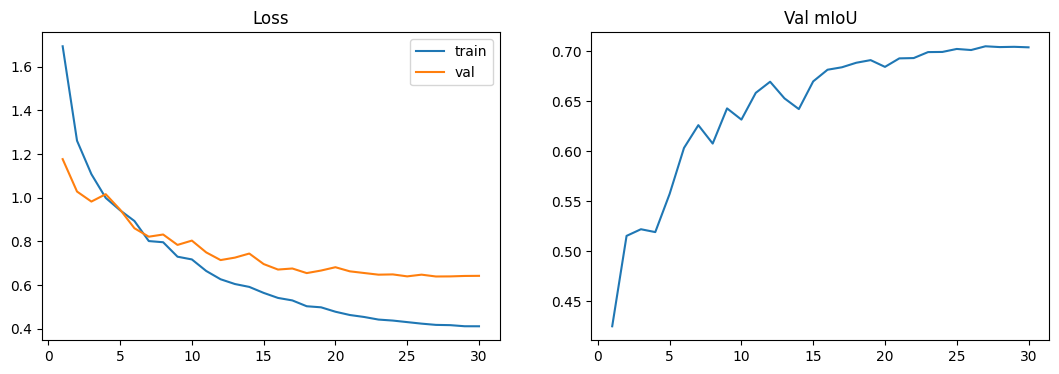

Best epoch 27 | mIoU 0.705 | pixel acc 0.873

Clutter    IoU 0.652
Building   IoU 0.909
Road       IoU 0.787
Tree       IoU 0.769
LowVeg     IoU 0.679
MovingCar  IoU 0.761
StaticCar  IoU 0.682
Human      IoU 0.399


In [5]:
import json, matplotlib.pyplot as plt

ep = [h['epoch'] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ep, [h['train_loss'] for h in history], label='train')
ax[0].plot(ep, [h['val_loss'] for h in history], label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(ep, [h['miou'] for h in history])
ax[1].set_title('Val mIoU')
plt.savefig(f'{DRIVE}/models/training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

best = max(history, key=lambda h: h['miou'])
print(f"Best epoch {best['epoch']} | mIoU {best['miou']:.3f} | pixel acc {best['pix_acc']:.3f}\n")
for c, v in zip(CLASSES, best['iou']):
    print(f'{c:10s} IoU {v:.3f}')

with open(f'{DRIVE}/models/history.json', 'w') as f:
    json.dump(history, f, indent=1)

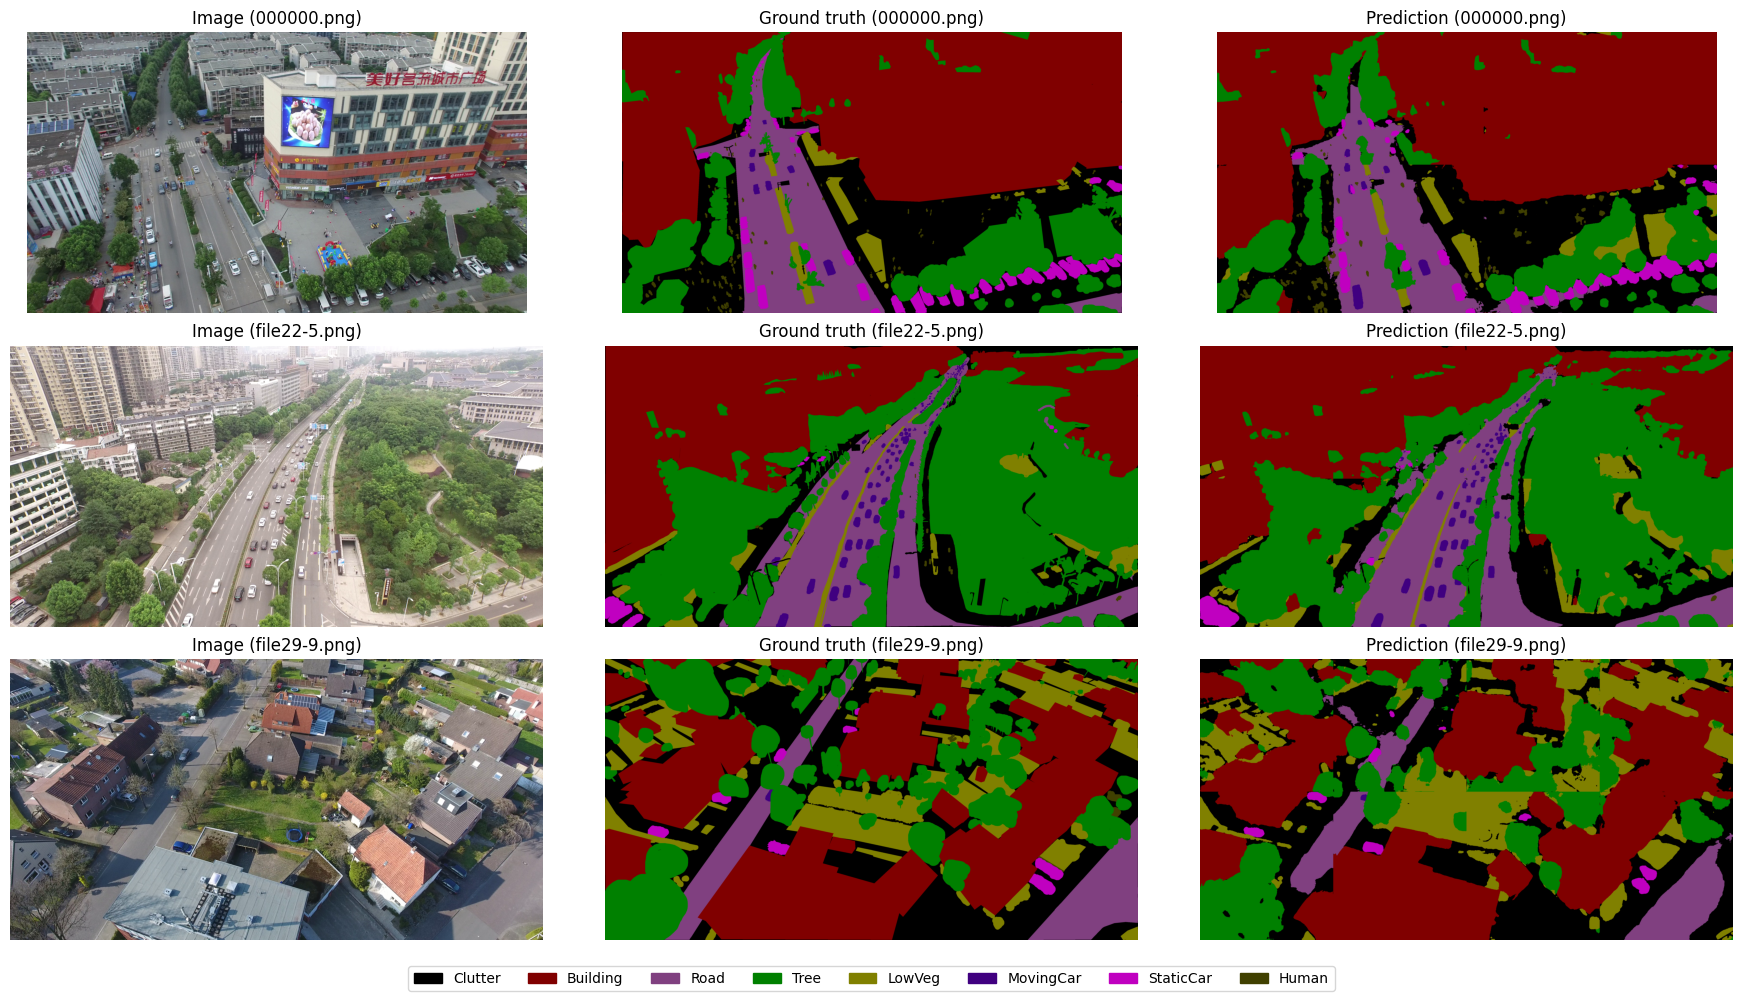

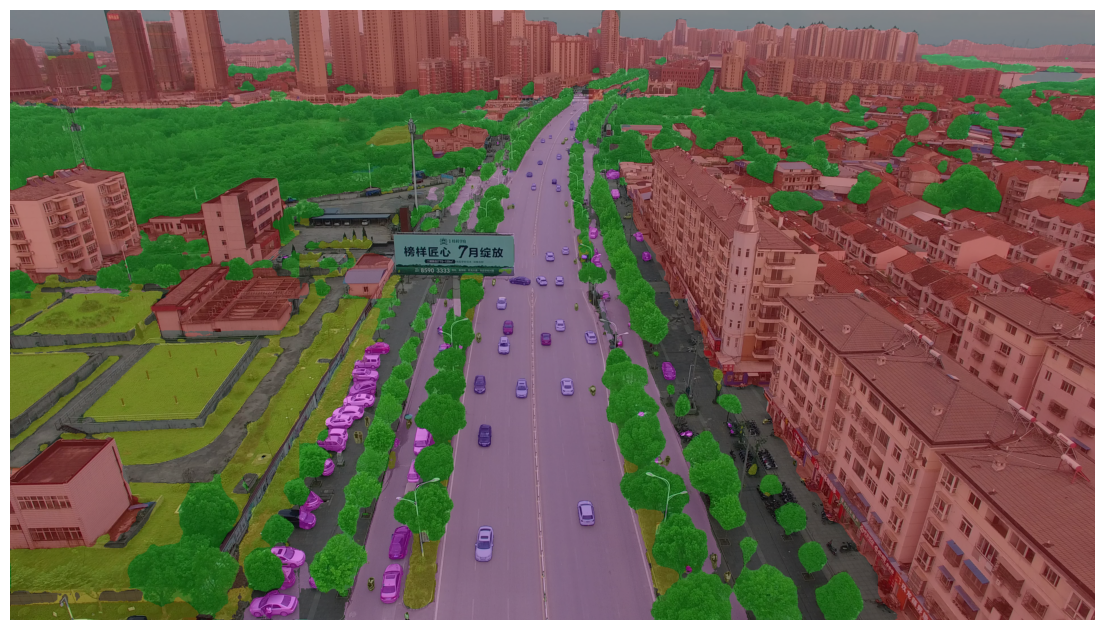

Saved to /content/drive/MyDrive/drone-mapping/outputs


In [6]:
import matplotlib.patches as mpatches

OUT_DIR = f'{DRIVE}/outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Extract only val and test images from the raw zip (takes a few minutes)
if not os.path.exists('/content/uavid/uavid_val'):
    !unzip -q -o "{DRIVE}/data/uavid-v1.zip" "uavid_val/*" "uavid_test/*" -d /content/uavid

model.load_state_dict(torch.load(CKPT_BEST, map_location=device))
model.eval()

PALETTE = np.array([(0,0,0), (128,0,0), (128,64,128), (0,128,0),
                    (128,128,0), (64,0,128), (192,0,192), (64,64,0)], np.uint8)

def starts(total, tile):
    s = list(range(0, total - tile + 1, tile))
    if s[-1] != total - tile:
        s.append(total - tile)
    return s

@torch.no_grad()
def predict_full(img_rgb, scale=0.5, tile=512):
    small = cv2.resize(img_rgb, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    H, W = small.shape[:2]
    norm = (small.astype(np.float32) / 255.0 - MEAN) / STD
    probs = torch.zeros(NUM_CLASSES, H, W, device=device)
    count = torch.zeros(1, H, W, device=device)
    for y in starts(H, tile):
        for x in starts(W, tile):
            t = torch.from_numpy(np.ascontiguousarray(norm[y:y+tile, x:x+tile].transpose(2, 0, 1)))
            with torch.amp.autocast('cuda'):
                out = model(t.unsqueeze(0).to(device))[0].float().softmax(0)
            probs[:, y:y+tile, x:x+tile] += out
            count[:, y:y+tile, x:x+tile] += 1
    pred = (probs / count).argmax(0).cpu().numpy().astype(np.uint8)
    return cv2.resize(pred, (img_rgb.shape[1], img_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)

legend = [mpatches.Patch(color=PALETTE[i] / 255, label=c) for i, c in enumerate(CLASSES)]

# Val: image | ground truth | prediction
val_imgs = sorted(glob.glob('/content/uavid/uavid_val/*/Images/*.png'))
fig, ax = plt.subplots(3, 3, figsize=(18, 10))
for row, i in enumerate([0, 35, 69]):
    img = cv2.cvtColor(cv2.imread(val_imgs[i]), cv2.COLOR_BGR2RGB)
    gt = cv2.cvtColor(cv2.imread(val_imgs[i].replace('/Images/', '/Labels/')), cv2.COLOR_BGR2RGB)
    pred = PALETTE[predict_full(img)]
    for col, (im, title) in enumerate([(img, 'Image'), (gt, 'Ground truth'), (pred, 'Prediction')]):
        ax[row, col].imshow(im); ax[row, col].set_title(f'{title} ({os.path.basename(val_imgs[i])})')
        ax[row, col].axis('off')
fig.legend(handles=legend, loc='lower center', ncol=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{OUT_DIR}/val_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

# Test: overlay for README (no labels exist for test)
test_img_path = sorted(glob.glob('/content/uavid/uavid_test/*/Images/*.png'))[0]
img = cv2.cvtColor(cv2.imread(test_img_path), cv2.COLOR_BGR2RGB)
overlay = cv2.addWeighted(img, 0.55, PALETTE[predict_full(img)], 0.45, 0)
cv2.imwrite(f'{OUT_DIR}/test_overlay.jpg', cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
plt.figure(figsize=(14, 8)); plt.imshow(overlay); plt.axis('off'); plt.show()
print('Saved to', OUT_DIR)

In [7]:
import shutil

if not os.path.exists('/content/uavid/uavid_val'):
    !unzip -q -o "{DRIVE}/data/uavid-v1.zip" "uavid_val/*" "uavid_test/*" -d /content/uavid

S = '/content/samples'
for sub in ['val/Images', 'val/Labels', 'test/Images']:
    os.makedirs(f'{S}/{sub}', exist_ok=True)

for p in sorted(glob.glob('/content/uavid/uavid_val/*/Images/*.png'))[::14]:
    shutil.copy(p, f'{S}/val/Images/')
    shutil.copy(p.replace('/Images/', '/Labels/'), f'{S}/val/Labels/')
for p in sorted(glob.glob('/content/uavid/uavid_test/seq21/Images/*.png')):
    shutil.copy(p, f'{S}/test/Images/')

os.makedirs(f'{DRIVE}/outputs', exist_ok=True)
!cd /content && zip -q -r "{DRIVE}/outputs/samples.zip" samples
!ls -lh "{DRIVE}/outputs"

total 199M
-rw------- 1 root root 195M Nov  3 12:36 samples.zip
-rw------- 1 root root 3.0M Nov  3 12:31 test_overlay.jpg
-rw------- 1 root root 1.4M Nov  3 12:30 val_comparison.png
